In [3]:
import glob
import numpy as np
import pandas as pd
import skimage as ski
import matplotlib.pyplot as plt
from skimage import io, filters
from skimage.filters import threshold_triangle, difference_of_gaussians
from skimage.morphology import disk, extrema
from skimage.measure import regionprops_table
from skimage.segmentation import watershed, mark_boundaries
from skimage.color import label2rgb,gray2rgb
from skimage.feature import peak_local_max
from scipy import ndimage
from scipy.ndimage import distance_transform_edt
import matplotlib


In [4]:
print(matplotlib.__version__)

3.10.9


In [2]:
PATH = '/Users/chann/Downloads/F1 Systems bio/Project/code/realistic_data/selected-tiles'

In [3]:
df = pd.read_csv("/Users/chann/Downloads/F1 Systems bio/Project/code/Results/Intermediates/Nuclei counting/nuclei_counting_4_DAPI_all_fov.csv")
print(df[:20])
df2 = df.iloc[:, [0, 5]].copy()
print(df2[:10])
df2.to_csv("/Users/chann/Downloads/F1 Systems bio/Project/code/Results/Intermediates/Nuclei counting/Nuclei_counting_4DAPI_mean.csv", index=False )

      Name   c01  c02  c03  c04  Mean   Unnamed: 6  Unnamed: 7  Unnamed: 8  \
0   X14_Y13  441  521  442  454    464         NaN         NaN         NaN   
1    X17_Y1  411  462  387  372    408         NaN         NaN         NaN   
2   X14_Y14  388  439  402  372    400         NaN         NaN         NaN   
3    X17_Y6  485  439  457  426    452         NaN         NaN         NaN   
4    X15_Y2  421  375  380  340    379         NaN         NaN         NaN   
5    X15_Y5  523  478  476  488    491         NaN         NaN         NaN   
6    X20_Y4  417  407  435  396    414         NaN         NaN         NaN   
7    X20_Y3  453  490  480  456    470         NaN         NaN         NaN   
8   X22_Y10  199  384  250  167    250         NaN         NaN         NaN   
9    X22_Y7  374  439  376  370    390         NaN         NaN         NaN   
10  X13_Y11  521  554  464  523    516         NaN         NaN         NaN   
11   X13_Y9  404  508  378  401    423         NaN         NaN  

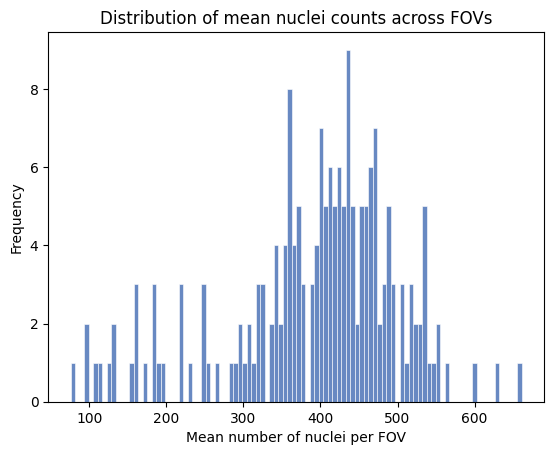

In [8]:
df2.iloc[:, 1].plot.hist(bins=100,color="#6889C2", edgecolor="white",linewidth=0.4)
plt.xlabel("Mean number of nuclei per FOV")
plt.ylabel("Frequency")
plt.title("Distribution of mean nuclei counts across FOVs")

plt.savefig("/Users/chann/Downloads/F1 Systems bio/Project/code/Results/Intermediates/Nuclei counting/histogram.png")
